In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [3]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = df['salary_year_avg'].to_numpy()

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

print(f'The mean, median, and standard deviation of the salary are {np.mean(y):.3f}, {np.median(y):.3f}, and {np.std(y):.3f} respectively.')

The mean, median, and standard deviation of the salary are 122390.906, 115000.000, and 47019.486 respectively.


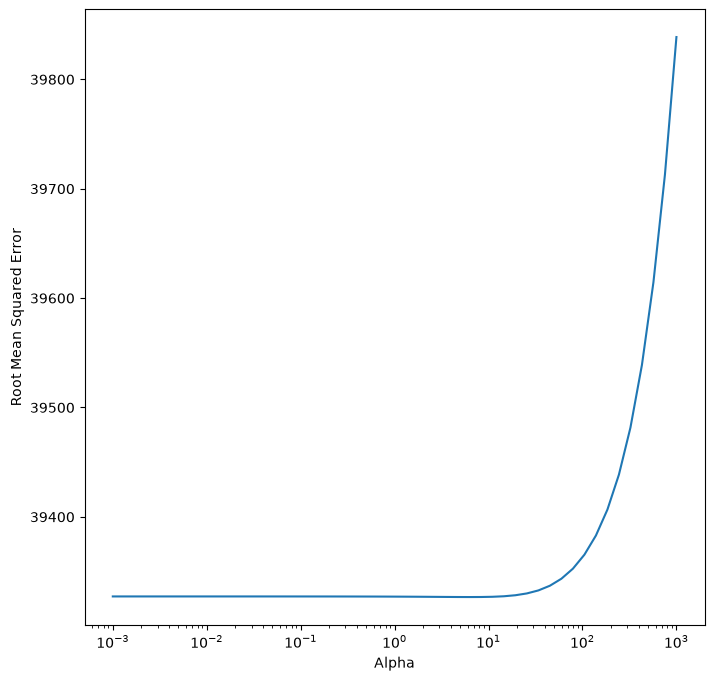

The best alpha value is 6.251 which gives a testing root mean squared error of 40300.159 and testing R squared score of 0.295.


,value
variable,
job_title_short_Senior Data Scientist,21426.840867
job_country_South Africa,15834.386922
job_country_United States,13902.050423
job_title_short_Senior Data Engineer,13373.740427
job_country_Sudan,11169.588414
job_via_LinkedIn,10824.642311
job_via_Built In,10375.713033
job_title_short_Software Engineer,8922.831144
job_title_short_Machine Learning Engineer,8667.288406


In [4]:
alphas = np.logspace(-3, 3, 50)
rmses = {}
for alpha in alphas:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Ridge_Regression()
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0), alpha=alpha)
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    average_rmse = np.mean(rmses_one_fold)
    rmses.update({alpha:average_rmse})
best_alpha = min(rmses, key=rmses.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(rmses.keys(), rmses.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

final_model = mlm.Ridge_Regression()
final_model.fit(X_training, y_training, alpha=best_alpha)
predictions = final_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))

print(f'The best alpha value is {best_alpha:.3f} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')
full_model = mlm.Ridge_Regression()
full_model.fit(X, y, alpha=best_alpha)
parameters = predictors
parameters_dictionary = dict(zip(parameters, full_model.parameters))
parameters_df = pd.DataFrame(parameters_dictionary)
parameters_df = pd.melt(parameters_df).set_index('variable', drop=True).sort_values(by='value', ascending=False)
display(parameters_df)

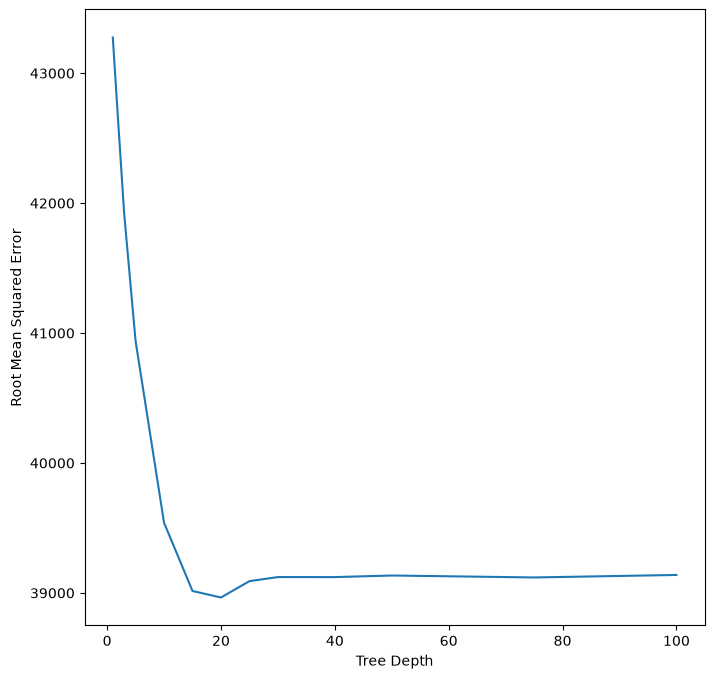

The best tree depth is 20 which gives a testing root mean squared error of 39969.776 and testing R squared score of 0.307.


,importance,direction
variables,,
job_title_short_Data Analyst,0.327871,-39367.338821
job_health_insurance,0.055661,12961.445031
job_title_short_Business Analyst,0.053129,-28603.355098
job_via_LinkedIn,0.029183,9803.757238
skills_excel,0.027082,-7781.021731
job_via_BeBee,0.024811,-14629.538920
job_title_short_Senior Data Analyst,0.022462,-9757.921971
job_via_Ladders,0.020579,4049.227494
job_posted_month_sine,0.019208,-557.175931


In [5]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rmses = []
for depth in depths:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append(np.mean(rmses_one_fold))
lowest_rmse = min(rmses)
best_depth = depths[rmses.index(lowest_rmse)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, rmses)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Tree(X.shape[1], max_depth=best_depth)
full_model.fit(X_training, y_training)
predictions = inner_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))

print(f'The best tree depth is {best_depth} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')
parameters = predictors
parameters_dictionary = {'variables':parameters, 'importance':full_model.features_importance(), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

In [ ]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 25).astype(np.int32))
rmses = []
for random_feature_number in random_feature_numbers:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Random_Forest(number_of_trees=25, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), random_feature_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_random_feature_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Random_Forest(number_of_trees=500, number_of_random_features=best_random_feature_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of random features is {best_random_feature_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'importance':full_model.features_importance(), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

KeyboardInterrupt: 